### Классификация двух рукавов спирали в TensorFlow Playground

Общие настройки: признаки X1 и X2, активация Tanh, без регуляризации, noise = 0, batch size = 10, доля тренировочных данных - 70%.

| Скрытые слои | Learning rate | Эпохи | Training loss | Test loss |
|-------|---:|---:|---:|---:|
| 4–4   | 0,03 | 1016 | 0,330 | 0,418 |
| 8–8   | 0,03 | 1002 | 0,068 | 0,168 |
| 8–8–8 | 0,03 | 1000 | 0,006 | 0,128 |
| 8–8–8 | 0,01 | 1001 | 0,088 | 0,225 |
| 8–8–8 | 0,01 | 3003 | 0,008 | 0,078 |

Последняя строка - продолжение предыдущего запуска. Лучший наблюдаемый результат получен для структуры 8-8-8 при learning rate = 0,01 после 3003 эпох. Результаты отдельных запусков также зависят от случайной инициализации весов.

![](dz_12.png)

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
# Загружаем обучающую и тестовую части MNIST
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print(f'{x_train_full.shape} x {y_train_full.shape}\n'
      f'{x_test.shape} x {y_test.shape}')

(60000, 28, 28) x (60000,)
(10000, 28, 28) x (10000,)


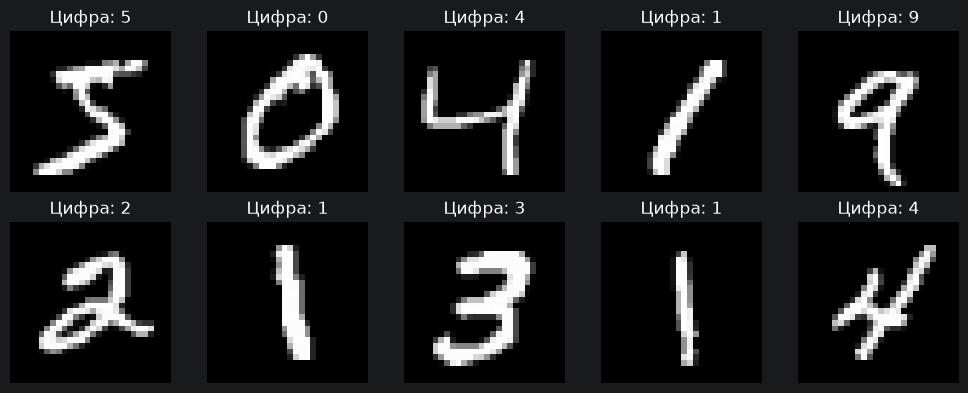

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i], cmap='gray')
    ax.set_title(f'Цифра: {y_train_full[i]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [4]:
# Выделяем validation из исходной обучающей части
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=10000,
    random_state=42,
    stratify=y_train_full
)

In [5]:
x_train = x_train.astype('float32') / 255.0
x_val = x_val.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print(f'{x_train.shape}, {x_val.shape}, {x_test.shape}\n'
      f'Диапазон train: {x_train.min()}, {x_train.max()}')

(50000, 28, 28), (10000, 28, 28), (10000, 28, 28)
Диапазон train: 0.0, 1.0


In [6]:
# Фиксируем случайность для воспроизводимости
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Настраиваем оптимизатор, функцию потерь и метрику
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9213 - loss: 0.2777 - val_accuracy: 0.9540 - val_loss: 0.1562
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9655 - loss: 0.1190 - val_accuracy: 0.9672 - val_loss: 0.1140
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9764 - loss: 0.0806 - val_accuracy: 0.9712 - val_loss: 0.1021
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9832 - loss: 0.0586 - val_accuracy: 0.9719 - val_loss: 0.0982
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9873 - loss: 0.0445 - val_accuracy: 0.9734 - val_loss: 0.0968
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9914 - loss: 0.0333 - val_accuracy: 0.9744 - val_loss: 0.1002
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9938 - loss: 0.0252 - val_accuracy: 0.9718 - val_loss: 0.1101
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9952 - loss: 0.0194 - 

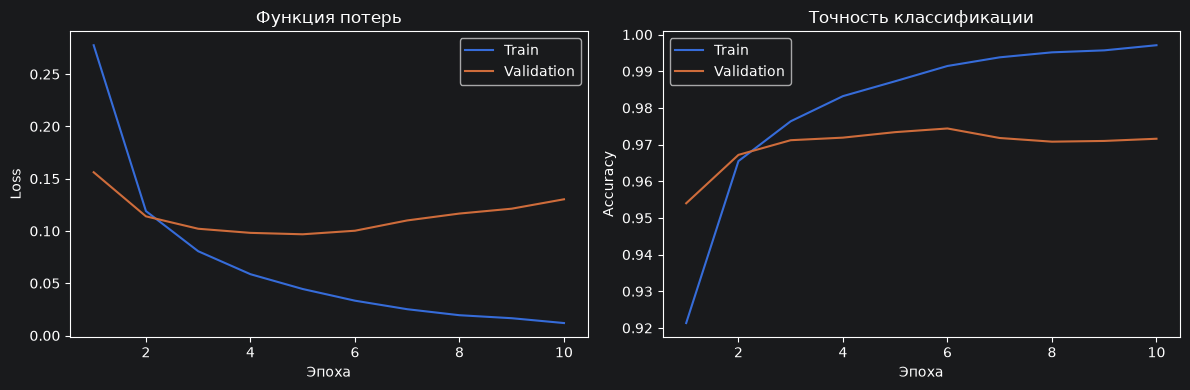

In [9]:
# Сравниваем динамику обучения на train и validation
epochs = np.arange(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history['loss'], label='Train')
axes[0].plot(epochs, history.history['val_loss'], label='Validation')
axes[0].set_title('Функция потерь')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(epochs, history.history['accuracy'], label='Train')
axes[1].plot(epochs, history.history['val_accuracy'], label='Validation')
axes[1].set_title('Точность классификации')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [10]:
# Создаём новую модель с той же архитектурой
tf.keras.utils.set_random_seed(42)

model_es = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_es.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
# Останавливаем обучение после трёх эпох без улучшения val_loss
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history_es = model_es.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping]
)

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9213 - loss: 0.2777 - val_accuracy: 0.9540 - val_loss: 0.1562
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9655 - loss: 0.1190 - val_accuracy: 0.9672 - val_loss: 0.1140
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9764 - loss: 0.0806 - val_accuracy: 0.9712 - val_loss: 0.1021
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9832 - loss: 0.0586 - val_accuracy: 0.9719 - val_loss: 0.0982
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9873 - loss: 0.0445 - val_accuracy: 0.9734 - val_loss: 0.0968
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9914 - loss: 0.0333 - val_accuracy: 0.9744 - val_loss: 0.1002
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9938 - loss: 0.0252 - val_accuracy: 0.9718 - val_loss: 0.1101
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9952 - loss: 0.0194 - 

In [12]:
# Сравниваем итоговые модели на test
test_results = []

for name, network in [
    ('Dense, 10 epochs', model),
    ('Dense, EarlyStopping', model_es)
]:
    test_loss, test_accuracy = network.evaluate(
        x_test, y_test, verbose=0
    )

    test_results.append({
        'Model': name,
        'Test loss': test_loss,
        'Test accuracy': test_accuracy
    })

pd.DataFrame(test_results)

,Model,Test loss,Test accuracy
0,"Dense, 10 epochs",0.107591,0.9743
1,"Dense, EarlyStopping",0.082167,0.9756


In [13]:
# Получаем предсказания модели с ранней остановкой
test_proba = model_es.predict(x_test, verbose=0)
test_pred = np.argmax(test_proba, axis=1)

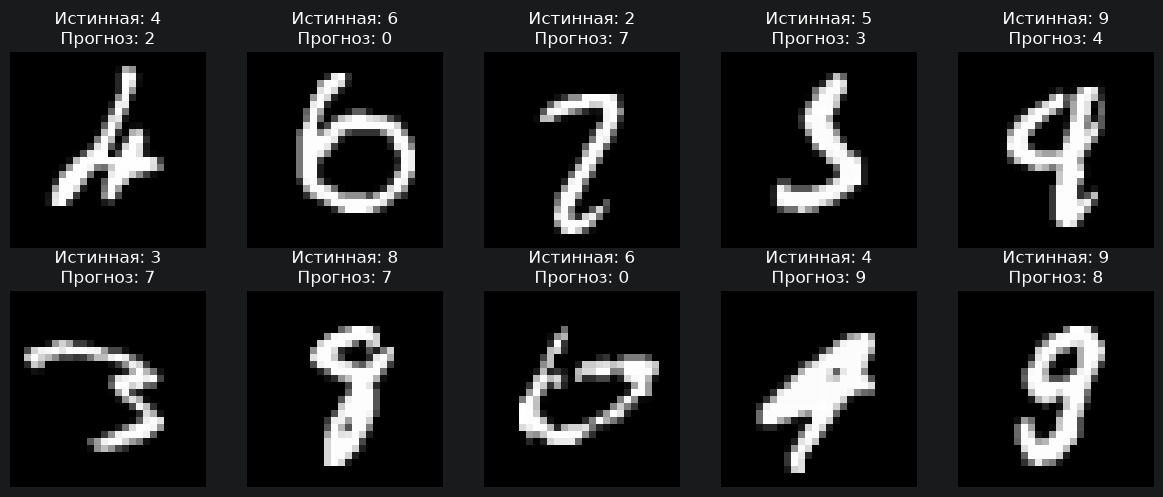

In [14]:
# Показываем первые 10 ошибочно распознанных изображений
error_indices = np.flatnonzero(test_pred != y_test)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, index in zip(axes.flat, error_indices[:10]):
    ax.imshow(x_test[index], cmap='gray')
    ax.set_title(
        f'Истинная: {y_test[index]}\nПрогноз: {test_pred[index]}'
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

Для классификации MNIST обучена сеть Dense со структурой 784 > 128 > 10 без сверточных слоев. После 10 эпох появились признаки переобучения. Ранняя остановка восстановила веса 5-й эпохи и повысила тестовую accuracy с 97,43% до 97,56%, снизив loss с 0,1076 до 0,0822. Примеры ошибок показывают путаницу между некоторыми похожими по написанию цифрами.